# IFT 6758 - Assignment 3

### Pt 1. Reddit Weekends

Assessment for this notebook:

- Histograms for basic counts, transformed counts, and central limit theorem counts
- Short answers (last section)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

In [3]:
from datetime import date
import scipy.stats as sp

In [4]:
import reddit_weekends

## 1. Load the data

Read JSON data and filter/clean the dataframe

In [5]:
raw_df = reddit_weekends.read_data("data/reddit-counts.json.gz")

In [6]:
raw_df.head()

,date,subreddit,comment_count
0,2012-02-20,newfoundland,7
1,2015-01-26,Manitoba,1
2,2013-09-07,Yukon,2
3,2014-02-15,saskatchewan,5
4,2014-07-06,canada,1652


In [7]:
# TODO: Complete these implementations in reddit_weekends.py
df = reddit_weekends.process_data(raw_df)
wd, we = reddit_weekends.split_data(df)

### T-Test

In [8]:
# TODO: Complete these implementations in reddit_weekends.py
p_ttest, p_wdNormal, p_weNormal, p_vartest = reddit_weekends.tests(wd, we, verbose=True)

p_value:	0.0
WD normality:	0.0
WE normality:	0.00152
Variance test:	0.04379


### Solution 1: Transforming the data could help us

Take a look at the histogram of the data. You'll notice that it's skewed: this is why it wasn't normally distributed in the last part. Try transforming the counts so that the data doesn't fail the normality test. Consider the following transformations:

np.log, np.exp, np.sqrt, counts**2

For each transformation, plot the new histogram (`reddit_weekends.draw_histogram()`) and run the `reddit_weekends.tests()` method to see if you can now use the t-test.

Note: None of these will pass the normality test for both distributions. The best you can get is a variable with normality issues, a good one; no equal variance issues.

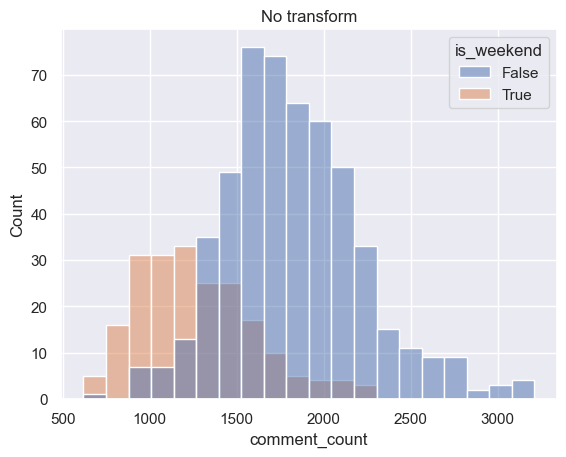

In [9]:
fig = reddit_weekends.draw_histogram(df, title="No transform")

p_value:	0.0
WD normality:	0.0004
WE normality:	0.31494
Variance test:	0.00042


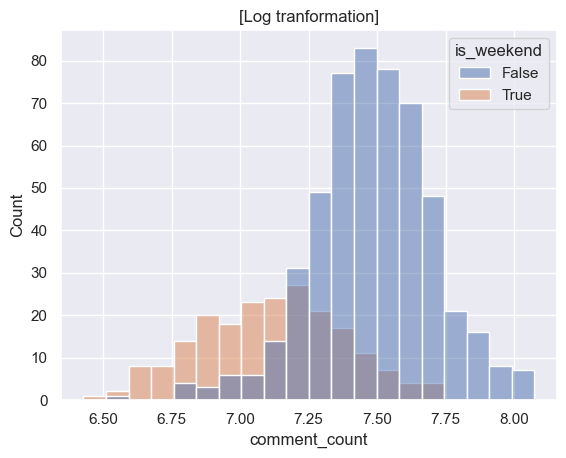

In [11]:
tmp_df = df.copy()

tmp_df["comment_count"]=np.log(tmp_df["comment_count"])


# TODO: Apply the transformations to the copied data (do not modify the original dataframe!)

# TODO: Draw the histogram
reddit_weekends.draw_histogram(tmp_df, title="[Log tranformation]")

# TODO: Run the tests again
_wd, _we = reddit_weekends.split_data(tmp_df)
_ = reddit_weekends.tests(_wd, _we, verbose=True)

/opt/anaconda3/envs/ift/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


KeyError: (('hue', np.False_),)

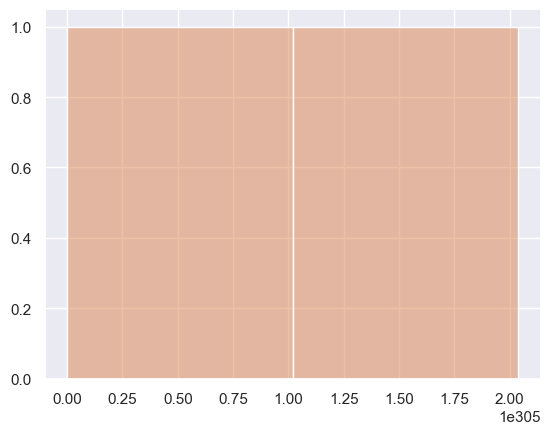

In [24]:
# Values are too big for this tranformation
tmp_df = df.copy()

tmp_df["comment_count"]=np.exp(tmp_df["comment_count"])

reddit_weekends.draw_histogram(tmp_df, title="[NP exp tranformation]")

# TODO: Run the tests again
_wd, _we = reddit_weekends.split_data(tmp_df)
_ = reddit_weekends.tests(_wd, _we, verbose=True)

p_value:	0.0
WD normality:	0.03687
WE normality:	0.10761
Variance test:	0.55605


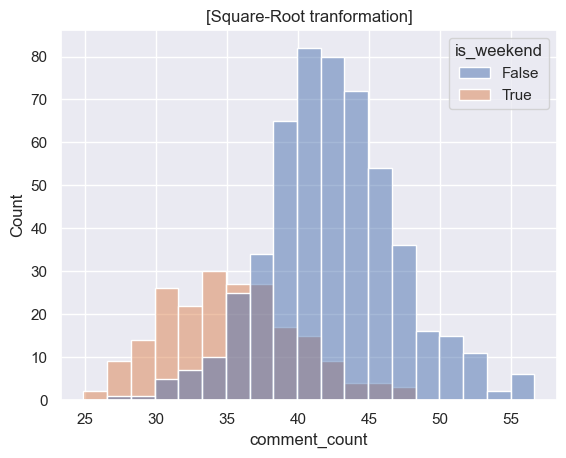

In [12]:
tmp_df = df.copy()

tmp_df["comment_count"]=np.sqrt(tmp_df["comment_count"])


# TODO: Apply the transformations to the copied data (do not modify the original dataframe!)

# TODO: Draw the histogram
reddit_weekends.draw_histogram(tmp_df, title="[Square-Root tranformation]")

# TODO: Run the tests again
_wd, _we = reddit_weekends.split_data(tmp_df)
_ = reddit_weekends.tests(_wd, _we, verbose=True)

p_value:	0.0
WD normality:	0.0
WE normality:	0.0
Variance test:	0.0


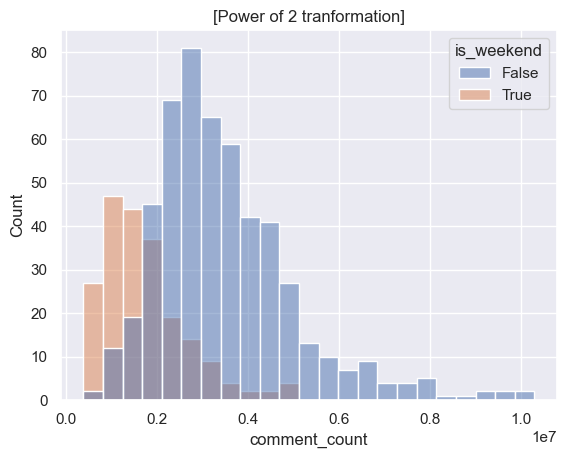

In [13]:
tmp_df = df.copy()

tmp_df["comment_count"]=tmp_df["comment_count"]**2


# TODO: Apply the transformations to the copied data (do not modify the original dataframe!)

# TODO: Draw the histogram
reddit_weekends.draw_histogram(tmp_df, title="[Power of 2 tranformation]")

# TODO: Run the tests again
_wd, _we = reddit_weekends.split_data(tmp_df)
_ = reddit_weekends.tests(_wd, _we, verbose=True)

# Correction 2: The central limit theorem could save us.

The central limit theorem says that if our numbers are large enough and we look at the sample means, then the result should be normal.
Let's try this: we'll combine all the weekdays and weekends in each year/week pair and take the average of their (untransformed) counts.

Tip: You can get a "year" and a "week number" from the first two values ​​returned by date.isocalendar(). This year and week number will give you an ID for the week. Use Pandas to group by this value and aggregate by taking the average.

Note: The year returned by isocalendar is not always the same as the year of the date (around the new year). Use the year from the isocalendar, which is correct in this case.

Check these values ​​for normality and equal variance. Apply a t-test if that makes sense. (Hint: yay!)

We should note that we're subtly changing the question here. The new question is more like, "Does the number of comments on weekends differ from the number of comments on weekdays for each week?"

In [21]:
# TODO: Complete these implementations in reddit_weekends.py
clt = reddit_weekends.central_limit_theorem(df)
clt.head()

,year,week,is_weekend,comment_count
0,2011,52,True,995.0
1,2012,1,False,1561.6
2,2012,1,True,1163.0
3,2012,2,False,2062.8
4,2012,2,True,1372.0


p_value:	0.0
WD normality:	0.30826
WE normality:	0.15295
Variance test:	0.2084


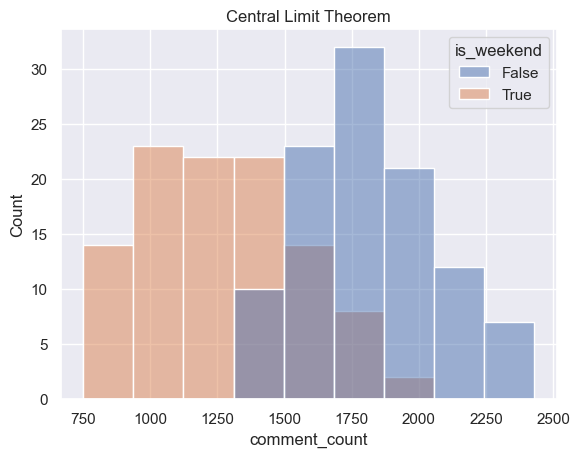

In [22]:
reddit_weekends.draw_histogram(clt, "Central Limit Theorem")

_wd, _we = reddit_weekends.split_data(clt)
_ = reddit_weekends.tests(_wd, _we, verbose=True)

## Correction 3: A nonparametric test could save us.

The other option we have in our toolbox: a statistical test that doesn't care as much about the shape of its input. The Mann–Whitney U test doesn't assume normally distributed values ​​or equal variance.

Perform a U test on the (initial, untransformed, unaggregated) counts. Note that we should be doing a two-tailed test here, which will correspond to the other analyses. Make sure the function arguments are correct.

Again, note that we are subtly changing the question again. If we reach a conclusion because of a U test, it's something like "it is not equally likely that there are more comments on weekends than on weekdays."

In [23]:
# TODO:  Complete these implementations in reddit_weekends.py
p_utest = reddit_weekends.mann_whitney_u_test(wd, we)
print(f"Mann-Whitney U-test p-value: {p_utest}")

Mann-Whitney U-test p-value: 8.624453234734304e-53


# Short Answers

1. Which of the four suggested transformations comes closest to satisfying the assumptions of a t-test?

*A two-sample t-test assumes that the two datasets are approximately normally distributed and have similar variances. Among the tranfromation proposed, the Square-Root transformation results comes closest to satisfying these conditions. The square-root transformed values for the weekend dataset appear to be normally distributed (p > 0.05). If the normality test for the weekdays dataset suggests that data are not normally distributed), its p value is the highest compared to other tranformations, barely under the 0.05 threshold (p = 0.03). Also, the variance test on the tranformed values indicates that the variances of the two datasets are not significantly different.*


2. I provided imprecise explanations in words of what the weekly test and the Mann-Whitney test were actually testing.
Do the same for the original t-test and the t-test of the transformed data.
In other words, describe what the conclusion would be if you could reject the null hypothesis in these tests.

*The H0 for a two-sample t-test is that the means of the two datasets are equal. If we were able to reject the H0 for the original data (p<0.005, normal distributions, similar variances) we would interpet this as evidence that the number of posts on weekends is statistically signficantly different from the number of posts on weekdays for the /canada thread across 2012-2013. Our conclusion would be the same if we had a t-test rejecting the H0 on the tranformed data.*


3. Of the four approaches, which do you think best answers the original question: "Are there different numbers of Reddit comments posted on weekdays and weekends?"
Briefly explain why. (It's not clear that there's a single correct answer to this question, but there are some wrong ones!)

*The above tests aim to answer this question using a sample with only data coming from a single Reddit thread (/r/canada) between years 2012 and 2013. Our tests though indicate that there is good possibility that the difference in volume of posts between weekdays and weekend days is statistically signficant. Yet, as the condition for the t-tests were not met, we can not say with certainty that the difference we observe for the two datasets (weekends and weekdays) is statistically significant. To extend this conclusion to other Reddit threads or time periods, we would need to test whether our subsample (/r/canada, 2012–2013) is representative of Reddit activity across threads and years.*


4. On average, on Reddit /r/canada, are there more comments posted on weekdays or weekends?

*We can say the following: we observe that in our sample, on average, there are more comments posted on weekdays than weekends for Reddit /r/canada comments posted accross 2012 and 2013. Since the conditions for t-tests are not met, we are not certain that this difference is statistically significant. We cannot make claims about other periods, threads or years.*